In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511058/notebook

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511058/notebook


In [2]:
import os
print(os.getcwd())
print(os.listdir("../src"))
print(len(os.listdir("../data/sintetis/citra")))

/content/drive/MyDrive/simuteh-2330511058/notebook
['buat_dataset_sintetis.py', 'utils_cv.py', '__pycache__']
60


In [3]:
import cv2, numpy as np
bercak = np.uint8([[[86, 178, 196]]])   # BGR
daun   = np.uint8([[[60, 136, 52]]])    # BGR
for nm, p in [("bercak", bercak), ("daun", daun)]:
    print(nm, "gray =", cv2.cvtColor(p, cv2.COLOR_BGR2GRAY)[0,0],
          "| Hue =", cv2.cvtColor(p, cv2.COLOR_BGR2HSV)[0,0,0])

bercak gray = 173 | Hue = 25
daun gray = 102 | Hue = 63


Kode 2.1 Pemisahan kanal dan Kontras Bercak

KB kanal B   : 1.43
KB kanal G   : 0.51
KB kanal R   : 7.77
KB kanal Gray: 3.70
KB kanal H   : 5.98
KB kanal S   : 1.21
KB kanal V   : 1.60


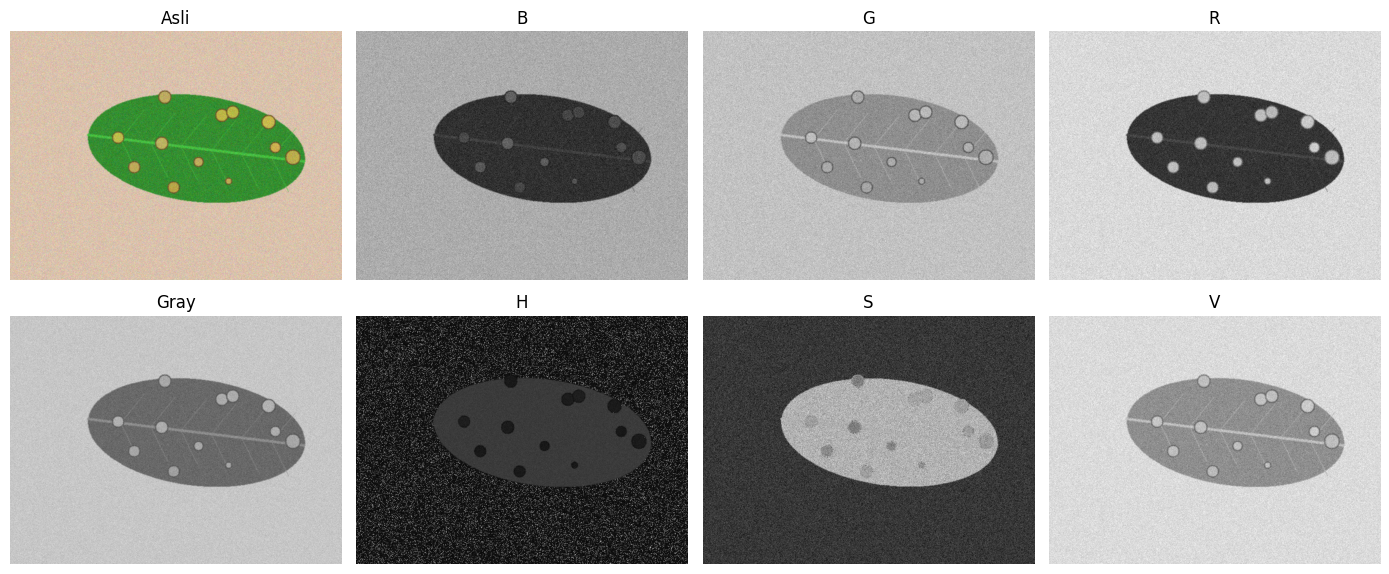

In [12]:
from utils_cv import kontras_bercak

nama = "teh_041.png"  # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")

md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

Kode 2.2 Sampling dan kuantisasi

In [13]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx,
                       interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)

    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")


# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah

    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=4.82
fx=0.2: ukuran (96, 128), KB=4.35
fx=0.1: ukuran (48, 64), KB=2.99
fx=0.05: ukuran (24, 32), KB=1.08
k=1: 2 level, KB=3.43
k=2: 4 level, KB=3.47
k=3: 7 level, KB=3.01
k=4: 12 level, KB=3.42
k=8: 172 level, KB=3.70


Kode 2.3 Rerata KB per kanal dan per kondisi

In [14]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}


label = pd.read_csv("../data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {k: kontras_bercak(c, m_d, m_b)
          for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)

tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.26  0.18   4.74  1.46  3.95  0.98  0.81
gelap           1.35  0.99  10.01  4.13  6.02  1.05  2.85
kontras_rendah  0.96  0.32   4.03  2.15  2.15  0.21  1.35
normal          2.04  0.59   9.11  4.12  7.36  1.40  2.00
terang          2.67  0.57   7.24  3.78  5.93  1.59  1.58


In [16]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}


label = pd.read_csv("../data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {k: kontras_bercak(c, m_d, m_b)
          for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)

tabel_kb.to_csv("../hasil/b2_kb_kanal_ringan.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.15  0.87  5.66  1.45  6.25  0.95  0.98
gelap           1.10  0.60  7.56  3.07  4.89  0.77  2.21
kontras_rendah  0.74  0.56  3.75  1.85  2.18  0.22  1.16
normal          1.56  0.31  7.92  2.97  7.06  0.96  1.37
terang          2.07  0.40  7.06  2.98  6.68  1.46  1.16


teh_021.png: kanal terbaik = R, KB = 6.99
teh_045.png: kanal terbaik = R, KB = 4.70


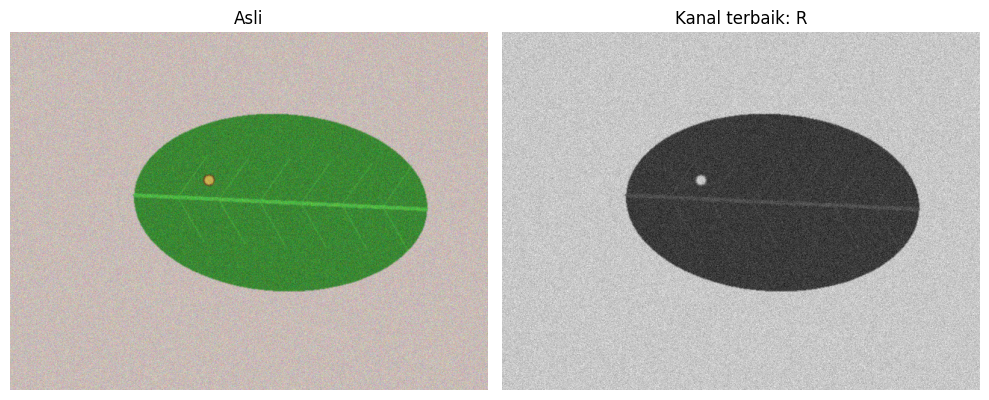

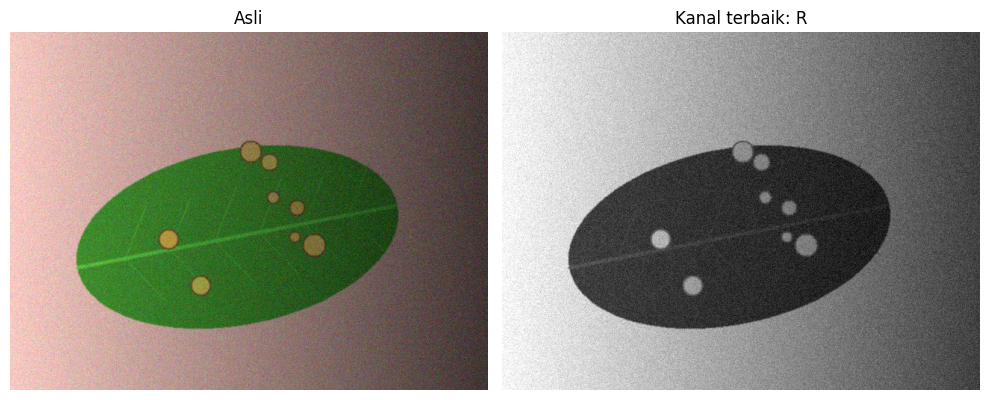

In [17]:
for nama in ["teh_021.png", "teh_045.png"]:
    img = baca(f"../data/sintetis/citra/{nama}")

    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

    kanal = semua_kanal(img)
    nilai_kb = {k: kontras_bercak(c, md, mb)
                for k, c in kanal.items()}

    terbaik = max(nilai_kb, key=nilai_kb.get)

    print(f"{nama}: kanal terbaik = {terbaik}, KB = {nilai_kb[terbaik]:.2f}")

    tampil([img, kanal[terbaik]],
           ["Asli", f"Kanal terbaik: {terbaik}"],
           baris=1, ukuran=(10, 4))

**Hasil Amati**

Berdasarkan hasil pengujian, kanal R memiliki nilai KB tertinggi pada kelas berat maupun kelas ringan. Pada gambar teh_021.png (ringan, normal), kanal terbaik adalah R dengan KB 6,99. Pada gambar teh_045.png (berat, bayangan), kanal terbaik juga R dengan KB 4,70. Hal ini menunjukkan bahwa kanal R tidak hanya menonjolkan bercak pada kelas berat, tetapi juga dapat menonjolkan bercak kecil pada kelas ringan. Dengan demikian, kanal R dapat digunakan untuk membantu membedakan bercak pada daun teh.
